# Lab 14-01 · Performance, Power and the Iron Law

Companion to [chapter 14-01](../../chapters/14-01-performance-power-iron-law.md). Four parts: an iron-law explorer; Amdahl and Gustafson curves with an overhead model; DVFS and the energy-optimal clock; and the means paradox. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar, brentq

## Part 1 · The iron law and an instruction mix

Each class has a frequency and a CPI. Compute the CPI, the execution time and each class's share of the time, then see what improving one class buys.

**Predict first:** loads are 25% of the instructions in Example 14-01.2. What share of the *time* do they take?

In [2]:
mix = {'ALU': (0.45, 1.0), 'load': (0.25, 2.5), 'store': (0.10, 1.0), 'branch': (0.20, 1.8)}
IC, f = 1e9, 3e9
def report(mix):
    cpi = sum(F * c for F, c in mix.values())
    print(f"CPI = {cpi:.3f}, time = {IC * cpi / f * 1e3:.1f} ms")
    for k, (F, c) in mix.items():
        print(f"  {k:6s}: {100 * F:4.0f}% of instructions, {100 * F * c / cpi:5.1f}% of time")
    return cpi
c0 = report(mix)
better = dict(mix, load=(0.25, 1.6))
c1 = report(better)
print(f"speedup from the better cache: {c0 / c1:.3f}")

CPI = 1.535, time = 511.7 ms
  ALU   :   45% of instructions,  29.3% of time
  load  :   25% of instructions,  40.7% of time
  store :   10% of instructions,   6.5% of time
  branch:   20% of instructions,  23.5% of time
CPI = 1.310, time = 436.7 ms
  ALU   :   45% of instructions,  34.4% of time
  load  :   25% of instructions,  30.5% of time
  store :   10% of instructions,   7.6% of time
  branch:   20% of instructions,  27.5% of time
speedup from the better cache: 1.172


## Part 2 · Amdahl, Gustafson and overheads

Plot fixed-problem (Amdahl) speedup for several parallel fractions, the scaled (Gustafson) speedup, and a model with a per-processor overhead that makes speedup peak and fall.

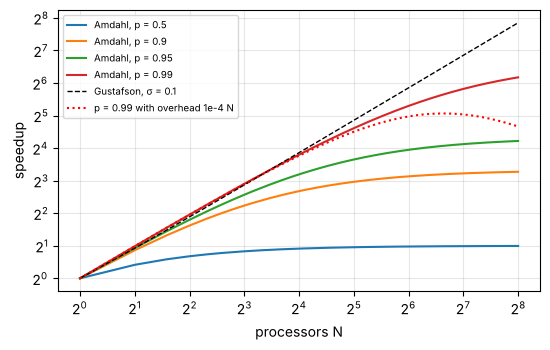

with overhead the speedup peaks at N = 99: 33.4x, then falls


In [3]:
N = np.arange(1, 257)
fig, ax = plt.subplots(figsize=(5.6, 3.6))
for p in (0.5, 0.9, 0.95, 0.99):
    ax.plot(N, 1 / ((1 - p) + p / N), label=f'Amdahl, p = {p}')
ax.plot(N, 0.1 + 0.9 * N, 'k--', lw=1, label='Gustafson, σ = 0.1')
c = 1e-4
S_ov = 1 / ((1 - 0.99) + 0.99 / N + c * N)
ax.plot(N, S_ov, 'r:', lw=1.5, label='p = 0.99 with overhead 1e-4 N')
ax.set_xscale('log', base=2); ax.set_yscale('log', base=2)
ax.set_xlabel('processors N'); ax.set_ylabel('speedup'); ax.legend(fontsize=7); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()
Nbest = N[np.argmax(S_ov)]
print(f"with overhead the speedup peaks at N = {Nbest}: {S_ov.max():.1f}x, then falls")

## Part 3 · DVFS and the energy-optimal clock

A core needs $V = 0.3 + 0.2f$ volts at $f$ GHz, with switched capacitance 1 nF and leakage 0.5 A (Problem 14-01.11). Plot the energy of a 10⁹-cycle task against frequency, split into dynamic and leakage parts.

**Predict first:** is the energy lowest at the lowest frequency?

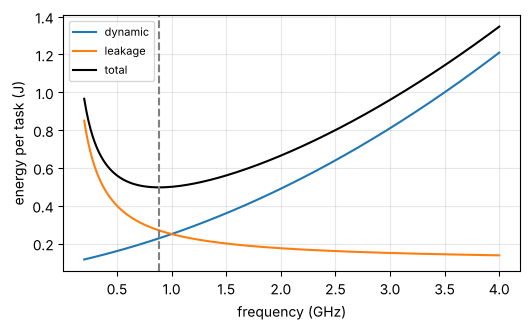

energy-optimal frequency 0.8864 GHz, minimum energy 0.4970 J


In [4]:
fg = np.linspace(0.2, 4.0, 400)
V = 0.3 + 0.2 * fg
E_dyn = 1e-9 * V**2 * 1e9
E_leak = V * 0.5 * (1e9 / (fg * 1e9))
fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.plot(fg, E_dyn, label='dynamic'); ax.plot(fg, E_leak, label='leakage'); ax.plot(fg, E_dyn + E_leak, 'k', label='total')
opt = minimize_scalar(lambda x: (0.3 + 0.2 * x)**2 + 0.5 * (0.3 + 0.2 * x) / x, bounds=(0.2, 4), method='bounded')
ax.axvline(opt.x, color='0.5', ls='--'); ax.set_xlabel('frequency (GHz)'); ax.set_ylabel('energy per task (J)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"energy-optimal frequency {opt.x:.4f} GHz, minimum energy {opt.fun:.4f} J")

## Part 4 · Which mean?

Two machines, five benchmarks. Compare the total time, the arithmetic mean of speed ratios and the geometric mean of speed ratios, each with two different reference machines.

In [5]:
TA = np.array([1.0, 1000.0, 50.0, 20.0, 5.0])
TB = np.array([10.0, 100.0, 40.0, 25.0, 4.0])
refs = {'reference R1': np.array([2.0, 500.0, 100.0, 40.0, 10.0]), 'reference R2': np.array([20.0, 50.0, 100.0, 40.0, 10.0])}
gm = lambda x: float(np.exp(np.mean(np.log(x))))
print(f"total time: A {TA.sum():.0f} s, B {TB.sum():.0f} s -> B is {TA.sum() / TB.sum():.2f}x faster on this workload")
for name, R in refs.items():
    am = np.mean(R / TB) / np.mean(R / TA)
    g = gm(R / TB) / gm(R / TA)
    print(f"{name}: arithmetic mean says B/A = {am:.3f}, geometric mean says B/A = {g:.3f}")

total time: A 1076 s, B 179 s -> B is 6.01x faster on this workload
reference R1: arithmetic mean says B/A = 1.388, geometric mean says B/A = 1.046
reference R2: arithmetic mean says B/A = 0.349, geometric mean says B/A = 1.046


## What to notice

- Loads are a quarter of the instructions but two-fifths of the time; the time profile, not the instruction count, says where to optimize.
- Every Amdahl curve flattens at $1/(1 - p)$, while the scaled speedup grows linearly; with any overhead that grows with $N$, speedup peaks and then falls.
- Energy per task has a minimum: below it, leakage over the longer run costs more than the lower voltage saves.
- The geometric mean of ratios gives the same B/A whichever reference is used; the arithmetic mean does not, and neither equals the workload's total-time ratio.